In [2]:
import os, time
import numpy as np, pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)
import features as F

SEED  = 42
MODES = ["host", "url"]          # host = main model, url = shortcut comparison
os.makedirs("../models", exist_ok=True)
os.makedirs("../results", exist_ok=True)

In [3]:
def load(mode):
    d = f"../data/features/{mode}"
    lex_tr = pd.read_csv(f"{d}/lex_train.csv")
    lex_va = pd.read_csv(f"{d}/lex_val.csv")
    y_tr   = np.load(f"{d}/y_train.npy")
    y_va   = np.load(f"{d}/y_val.npy")

    # TF-IDF needs the text itself. Rebuild it exactly the way Phase 4 did,
    # so the rows line up with the saved features and labels.
    tr = pd.read_csv("../data/splits/train.csv")
    va = pd.read_csv("../data/splits/val.csv")
    if mode == "host":
        tr, _ = F.to_host_dataset(tr)
        va, _ = F.to_host_dataset(va)
    txt_tr = tr["URL"].map(lambda u: F.to_text(u, mode)).values
    txt_va = va["URL"].map(lambda u: F.to_text(u, mode)).values

    # Alignment checks: if either fails, Phase 4 and Phase 5 disagree on row order.
    assert len(lex_tr) == len(y_tr) == len(txt_tr), "train row counts differ"
    assert len(lex_va) == len(y_va) == len(txt_va), "val row counts differ"
    assert (tr["label"].values == y_tr).all() and (va["label"].values == y_va).all()
    assert list(lex_tr.columns) == list(lex_va.columns)

    return dict(lex_tr=lex_tr, lex_va=lex_va, txt_tr=txt_tr, txt_va=txt_va,
                y_tr=y_tr, y_va=y_va)

data = {m: load(m) for m in MODES}
for m, d in data.items():
    print(f"{m:4s}  train {len(d['y_tr']):>7,}  val {len(d['y_va']):>6,}  "
          f"phishing share (val) {d['y_va'].mean():.3f}  "
          f"lexical features {d['lex_tr'].shape[1]}")

host  train 152,861  val 32,763  phishing share (val) 0.383  lexical features 17
url   train 164,758  val 35,306  phishing share (val) 0.427  lexical features 21


In [ ]:
def make_models():
    return {
        "lr_lex": make_pipeline(
            StandardScaler(),                       # fitted on train only, inside the pipeline
            LogisticRegression(max_iter=2000, random_state=SEED)),
        "rf_lex": RandomForestClassifier(
            n_estimators=300, n_jobs=-1, random_state=SEED),
        "lr_tfidf": make_pipeline(
            TfidfVectorizer(analyzer="char", ngram_range=(2, 5), min_df=3,
                            sublinear_tf=True, lowercase=False, dtype=np.float32),
            LogisticRegression(max_iter=2000, C=4.0, random_state=SEED)),
    }

def inputs(name, d, split):
    """Lexical models take the feature table; the TF-IDF model takes raw text."""
    return d[f"txt_{split}"] if name == "lr_tfidf" else d[f"lex_{split}"]

def scores(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"precision": precision_score(y, pred, zero_division=0),
            "recall":    recall_score(y, pred),
            "f1":        f1_score(y, pred),
            "roc_auc":   roc_auc_score(y, p),
            "fpr":       fp / (fp + tn),            # legit sites wrongly flagged
            "fp": int(fp), "fn": int(fn)}

In [5]:
rows, probs, fitted = [], {}, {}
for mode in MODES:
    d = data[mode]
    for name, model in make_models().items():
        t0 = time.time()
        model.fit(inputs(name, d, "tr"), d["y_tr"])
        fit_s = time.time() - t0
        p = model.predict_proba(inputs(name, d, "va"))[:, 1]

        rows.append({"mode": mode, "model": name, **scores(d["y_va"], p),
                     "fit_seconds": round(fit_s, 1)})
        probs[(mode, name)] = p
        fitted[(mode, name)] = model
        joblib.dump(model, f"../models/{mode}_{name}.joblib")       # reused in Phase 7
        np.save(f"../results/val_probs_{mode}_{name}.npy", p)        # for the CNN-vs-baseline ROC plot
        print(f"done: {mode:4s} {name:9s} ({fit_s:.0f}s)")

results = pd.DataFrame(rows)
results.to_csv("../results/phase5_baselines.csv", index=False)
results.round(4)

done: host lr_lex    (0s)
done: host rf_lex    (4s)
done: host lr_tfidf  (5s)
done: url  lr_lex    (0s)
done: url  rf_lex    (3s)
done: url  lr_tfidf  (9s)


,mode,model,precision,recall,f1,roc_auc,fpr,fp,fn,fit_seconds
0,host,lr_lex,0.9097,0.6595,0.7647,0.8568,0.0406,821,4271,0.2
1,host,rf_lex,0.9270,0.6605,0.7714,0.8586,0.0322,652,4258,3.6
2,host,lr_tfidf,0.9132,0.7120,0.8002,0.9116,0.0420,849,3612,5.1
3,url,lr_lex,0.9993,0.9927,0.9960,0.9986,0.0005,11,110,0.1
4,url,rf_lex,0.9989,0.9952,0.9970,0.9986,0.0008,17,73,3.4
5,url,lr_tfidf,0.9662,0.7973,0.8737,0.9429,0.0208,420,3056,9.1


In [6]:
cols = data["host"]["lex_tr"].columns

lr = fitted[("host", "lr_lex")][-1]               # last pipeline step = the LogisticRegression
coef = pd.Series(lr.coef_[0], index=cols).sort_values()
rf_imp = pd.Series(fitted[("host", "rf_lex")].feature_importances_, index=cols)

print("Logistic regression coefficients (standardized; + pushes toward phishing):")
print(coef.round(3).to_string())
print("\nRandom forest importances (top 10):")
print(rf_imp.sort_values(ascending=False).head(10).round(3).to_string())

Logistic regression coefficients (standardized; + pushes toward phishing):
sld_len          -2.271
tld_edu_gov      -0.957
n_dots           -0.490
tld_org_net      -0.235
tld_cctld        -0.127
entropy          -0.122
tld_com          -0.043
is_ip             0.013
tld_ip            0.013
n_suspicious      0.198
tld_other_gtld    0.373
n_hyphens         0.509
n_subdomains      0.653
tld_abused        1.073
host_len          1.729
len               1.729
n_digits          1.957

Random forest importances (top 10):
n_digits          0.174
entropy           0.119
n_dots            0.113
len               0.103
tld_abused        0.100
host_len          0.096
n_subdomains      0.084
sld_len           0.058
tld_other_gtld    0.041
tld_edu_gov       0.029


In [7]:
tf_pipe = fitted[("host", "lr_tfidf")]
vec, clf = tf_pipe[0], tf_pipe[-1]
names = np.array(vec.get_feature_names_out())
w = clf.coef_[0]
order = np.argsort(w)

print(f"TF-IDF vocabulary size: {len(names):,}")
print("\nTop phishing n-grams:   ", [names[i] for i in order[::-1][:25]])
print("\nTop legitimate n-grams: ", [names[i] for i in order[:25]])

TF-IDF vocabulary size: 237,112

Top phishing n-grams:    ['.cf', '.ga', '.ml', '.w', '.top', '.t', '1.', '.g', '.gq', '.x', 'gq', 'dns', '.jp.', '.we', 'jp.', 'cf', '.y', 'o.jp.', '.m', '.sit', '.p', 'jpo', '.site', '2.', 'ml']

Top legitimate n-grams:  ['.go', '.gov', '.edu', '.jp', '.ed', '.ie', '.it', '.gr', '.de', 'gov', '.cz', '.se', '.ca', '.sk', '.be', '.hr', '.org', '.or', '.tv', '.dk', '.ac.', '.pt', '.bg', '.com', '.rs']


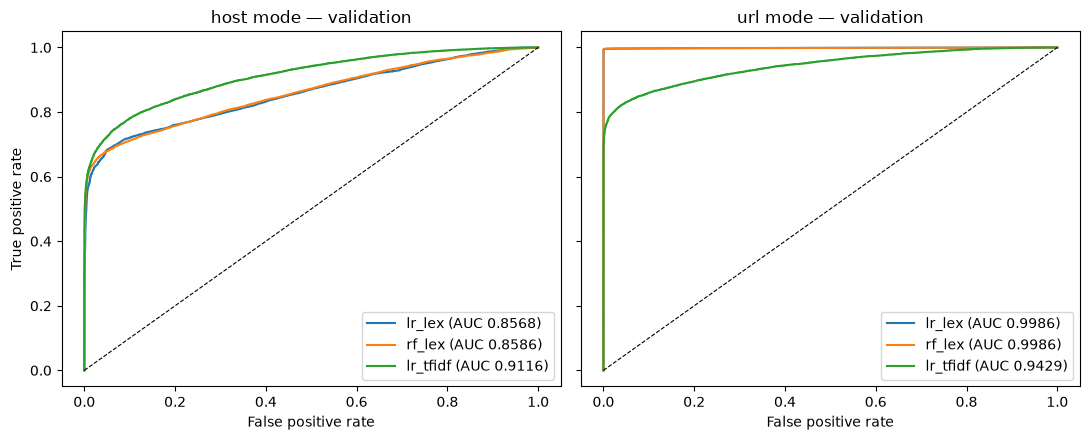

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, mode in zip(axes, MODES):
    y = data[mode]["y_va"]
    for name in ["lr_lex", "rf_lex", "lr_tfidf"]:
        fpr, tpr, _ = roc_curve(y, probs[(mode, name)])
        auc = results.query("mode == @mode and model == @name")["roc_auc"].iloc[0]
        ax.plot(fpr, tpr, label=f"{name} (AUC {auc:.4f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{mode} mode — validation")
    ax.set_xlabel("False positive rate")
    ax.legend(loc="lower right")
axes[0].set_ylabel("True positive rate")
plt.tight_layout()
plt.savefig("../results/phase5_roc.png", dpi=150)
plt.show()

In [11]:
host = results.query("mode == 'host'").set_index("model")
best = host["f1"].idxmax()
print(f"Best host-mode baseline: {best}")
print(host.loc[best, ["precision", "recall", "f1", "roc_auc", "fpr"]].round(4).to_string())

Best host-mode baseline: lr_tfidf
precision    0.9132
recall       0.7120
f1           0.8002
roc_auc      0.9116
fpr          0.0420


In [12]:
from sklearn.preprocessing import OneHotEncoder

def recall_at_fpr(y, p, target=0.01):
    fpr, tpr, _ = roc_curve(y, p)
    return tpr[fpr <= target].max()

results["recall@1%fpr"] = [recall_at_fpr(data[r["mode"]]["y_va"], probs[(r["mode"], r["model"])])
                           for _, r in results.iterrows()]
results.to_csv("../results/phase5_baselines.csv", index=False)
print(results[["mode", "model", "f1", "roc_auc", "recall@1%fpr"]].round(4), "\n")

# TLD-only baseline: how far does the last label of the host get you on its own?
d = data["host"]
tld = lambda arr: pd.DataFrame({"tld": [t.rsplit(".", 1)[-1] for t in arr]})
tld_model = make_pipeline(
    OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=3),
    LogisticRegression(max_iter=2000, random_state=SEED))
tld_model.fit(tld(d["txt_tr"]), d["y_tr"])
p_tld = tld_model.predict_proba(tld(d["txt_va"]))[:, 1]
s = scores(d["y_va"], p_tld)
print(f"TLD-only:  f1 {s['f1']:.4f}  roc_auc {s['roc_auc']:.4f}  "
      f"recall@1%fpr {recall_at_fpr(d['y_va'], p_tld):.4f}\n")

# What the best baseline misses
p, y, txt = probs[("host", "lr_tfidf")], d["y_va"], pd.Series(d["txt_va"])
fn = txt[(y == 1) & (p < 0.5)]
print(f"Missed phishing hosts: {len(fn):,}. Random sample:")
print(fn.sample(min(25, len(fn)), random_state=SEED).to_string(index=False))

   mode     model      f1  roc_auc  recall@1%fpr
0  host    lr_lex  0.7647   0.8568        0.5757
1  host    rf_lex  0.7714   0.8586        0.6123
2  host  lr_tfidf  0.8002   0.9116        0.6247
3   url    lr_lex  0.9960   0.9986        0.9958
4   url    rf_lex  0.9970   0.9986        0.9965
5   url  lr_tfidf  0.8737   0.9429        0.7757 

TLD-only:  f1 0.5791  roc_auc 0.7850  recall@1%fpr 0.3305

Missed phishing hosts: 3,612. Random sample:
              goledeals.com
           mirrorsupply.com
         malaysianscoop.com
               quickful.com
              mas.psawi.com
      kopalpublicschool.com
               maccaffe.com
              vibetronic.id
               bibigreen.ru
             panoramafe.com
 reziswang.marshbodyart.com
                  gk725.com
                    mrwu.at
      megawindbrasil.com.br
                 seafiw.com
stellahuang.myportfolio.com
              stopherau.com
           antos.psarbaw.pl
    kleinelandhausidylle.ch
                   